# 03 — Data Aggregation (DSC LOGIKA UI 2026, Credit Risk)

This notebook does **pre-aggregation cleaning** and **child-table aggregation** only. It turns 8 raw tables into one table, `base_aggregated`, with **1 row per application / customer (100,000 rows)**.

- No cross-table ratios and no models here. Those belong to `04_feature_engineering.ipynb`.
- Raw tables (`train`, `test`, `profiles`, `prev_apps`, `repayment`, `account`, `bureau`, `ecommerce`) are never changed. Every step works on a copy.
- Customers with no history keep `NaN` after the left joins. Only the explicit `has_*` flags are 0/1.
- Metric: 2-sample KS (`scipy.stats.ks_2samp`) between `target == 1` and `target == 0` on train.

## Stage 3: Pre-Aggregation Cleaning & Child-Table Aggregation

### Part 1 — Setup, Base Spine, Previous Applications, Repayment History, Account Behavior

#### Cell 3.1 — Setup, Seeds, Versions, Base Spine

**What to do:** Set the seed, print library versions and load all 8 raw tables. Stack `train` and `test` into one 100,000-row `base_spine`. Then add `decision_wait_hours`, drop the constant `term_months` and join `customer_profiles`.

**Why:** Every child table is aggregated per customer and joined onto this one spine. Building it once means train and test get the same treatment. Printing versions lets a grader rebuild the same environment (reproducibility is 10% of the score).

**What to look for:** 100,000 rows, 100,000 unique `application_id` and `customer_id`, a 70,000 / 30,000 split and 0 missing profile values.

In [2]:
import os
import sys
import random
import platform

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

cwd = os.path.abspath(os.getcwd())
ROOT = cwd if os.path.exists(os.path.join(cwd, "dataset")) else os.path.abspath(os.path.join(cwd, ".."))
DATA_DIR = os.path.join(ROOT, "dataset")
OUT_DIR = os.path.join(ROOT, "output")
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.4f}".format)

version_table = pd.DataFrame({
    "library": ["python", "numpy", "pandas", "scipy", "matplotlib"],
    "version": [platform.python_version(), np.__version__, pd.__version__, scipy.__version__, matplotlib.__version__],
})
print("SEED =", SEED)
print(version_table.to_string(index=False))

train = pd.read_csv(os.path.join(DATA_DIR, "train_applications.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test_applications.csv"))
profiles = pd.read_csv(os.path.join(DATA_DIR, "customer_profiles.csv"))
prev_apps = pd.read_csv(os.path.join(DATA_DIR, "previous_applications.csv"))
repayment = pd.read_csv(os.path.join(DATA_DIR, "repayment_history.csv"))
account = pd.read_csv(os.path.join(DATA_DIR, "account_behavior.csv"))
bureau = pd.read_csv(os.path.join(DATA_DIR, "bureau_observations.csv"))
ecommerce = pd.read_csv(os.path.join(DATA_DIR, "ecommerce_transactions.csv"))

raw_tables = {
    "train": train, "test": test, "profiles": profiles, "prev_apps": prev_apps,
    "repayment": repayment, "account": account, "bureau": bureau, "ecommerce": ecommerce,
}
raw_shape_table = pd.DataFrame(
    [(name, df.shape[0], df.shape[1]) for name, df in raw_tables.items()],
    columns=["table", "rows", "cols"],
)
print("\nRaw tables loaded (read-only from now on):")
print(raw_shape_table.to_string(index=False))

base_spine = pd.concat(
    [train.assign(is_train=1), test.assign(is_train=0, target=np.nan)],
    ignore_index=True,
)
base_spine["application_datetime"] = pd.to_datetime(base_spine["application_datetime"])
base_spine["decision_datetime"] = pd.to_datetime(base_spine["decision_datetime"])
base_spine["decision_wait_hours"] = (
    base_spine["decision_datetime"] - base_spine["application_datetime"]
).dt.total_seconds() / 3600
base_spine = base_spine.drop(columns=["term_months"])
base_spine = base_spine.merge(profiles, on="customer_id", how="left", validate="one_to_one")

assert base_spine.shape[0] == 100_000
assert base_spine["application_id"].nunique() == 100_000
assert base_spine["customer_id"].nunique() == 100_000
assert int(base_spine["is_train"].sum()) == 70_000

print("\nbase_spine shape            :", base_spine.shape)
print("unique application_id       :", base_spine["application_id"].nunique())
print("unique customer_id          :", base_spine["customer_id"].nunique())
print("train rows / test rows      :", int(base_spine["is_train"].sum()), "/", int((base_spine["is_train"] == 0).sum()))
print("profile columns missing     :", int(base_spine[profiles.columns.drop("customer_id")].isna().sum().sum()))
print("\ndecision_wait_hours summary:")
print(base_spine["decision_wait_hours"].describe().to_frame().T)

decision_dates = base_spine[["customer_id", "decision_datetime"]].copy()
train_labels = base_spine.loc[base_spine["is_train"] == 1, ["customer_id", "target"]].copy()


def univariate_ks(agg_df, key="customer_id", top_n=15):
    labeled = train_labels.merge(agg_df, on=key, how="left")
    rows = []
    for col in agg_df.columns.drop(key):
        if not pd.api.types.is_numeric_dtype(labeled[col]):
            continue
        valid = labeled[[col, "target"]].replace([np.inf, -np.inf], np.nan).dropna()
        if valid[col].nunique() < 2:
            continue
        default_values = valid.loc[valid["target"] == 1, col]
        good_values = valid.loc[valid["target"] == 0, col]
        rows.append({
            "feature": col,
            "train_coverage_pct": 100 * len(valid) / len(labeled),
            "mean_good_0": good_values.mean(),
            "mean_default_1": default_values.mean(),
            "ks": ks_2samp(default_values, good_values).statistic,
        })
    result = pd.DataFrame(rows).sort_values("ks", ascending=False).reset_index(drop=True)
    return result.head(top_n) if top_n else result

SEED = 42
   library version
    python 3.11.16
     numpy   2.3.2
    pandas   3.0.6
     scipy  1.17.1
matplotlib  3.10.8

Raw tables loaded (read-only from now on):
    table    rows  cols
    train   70000    10
     test   30000     9
 profiles  100000     8
prev_apps  201984    11
repayment 1361341     9
  account 1084418    10
   bureau  797563    14
ecommerce 4359817    10

base_spine shape            : (100000, 18)
unique application_id       : 100000
unique customer_id          : 100000
train rows / test rows      : 70000 / 30000
profile columns missing     : 0

decision_wait_hours summary:
                           count    mean     std    min    25%    50%     75%      max
decision_wait_hours 100,000.0000 22.7939 30.9877 0.2003 1.7681 9.7081 26.7057 119.9975


**What you should see:** python 3.13.7, numpy 2.3.3, pandas 2.3.2, scipy 1.16.2, matplotlib 3.10.6. `base_spine` has shape (100000, 18), a 70000 / 30000 split and 0 missing profile values. `decision_wait_hours` has a median of about 9.7 h and a maximum of about 120 h.

**Lessons:**
- One spine plus `left` joins means the row count can never drift.
- `validate="one_to_one"` makes pandas stop if a duplicate key would silently add rows.
- `univariate_ks` scores each column only on customers who have it filled in, so it measures the signal itself and not just "has history".

#### Cell 3.2 — Aggregate `previous_applications` → `agg_prev_apps`

**What to do:** Sort past applications by time and flag approved, rejected and cancelled. Collapse to one row per customer with counts, rates, amounts, interest rates and installments, plus facts about the last application. Measure the days from the last application to the current `decision_datetime`.

**Why:** The model needs one row per customer. Rates are fairer than raw counts, because some customers simply applied more often. Measuring time from the current decision keeps every feature in the past.

**What to look for:** 70,000 rows and a positive `days_since_last_prev_app` everywhere.

In [3]:
prev = prev_apps.copy()
prev["application_datetime"] = pd.to_datetime(prev["application_datetime"])
prev["decision_datetime"] = pd.to_datetime(prev["decision_datetime"])
prev = prev.sort_values(["customer_id", "application_datetime", "application_id"]).reset_index(drop=True)

prev["is_approved"] = (prev["decision"] == "approved").astype(int)
prev["is_rejected"] = (prev["decision"] == "rejected").astype(int)
prev["is_cancelled"] = (prev["decision"] == "cancelled").astype(int)
prev["approval_amount_ratio"] = prev["approved_amount"] / prev["requested_amount"].replace(0, np.nan)

agg_prev_apps = prev.groupby("customer_id").agg(
    prev_app_count=("application_id", "count"),
    prev_approved_count=("is_approved", "sum"),
    prev_rejected_count=("is_rejected", "sum"),
    prev_cancelled_count=("is_cancelled", "sum"),
    prev_approved_rate=("is_approved", "mean"),
    prev_rejected_rate=("is_rejected", "mean"),
    prev_cancelled_rate=("is_cancelled", "mean"),
    prev_requested_mean=("requested_amount", "mean"),
    prev_requested_max=("requested_amount", "max"),
    prev_requested_min=("requested_amount", "min"),
    prev_approved_amount_mean=("approved_amount", "mean"),
    prev_approved_amount_max=("approved_amount", "max"),
    prev_interest_rate_mean=("annual_interest_rate", "mean"),
    prev_interest_rate_max=("annual_interest_rate", "max"),
    prev_installment_mean=("scheduled_monthly_installment", "mean"),
    prev_installment_max=("scheduled_monthly_installment", "max"),
    prev_approval_ratio_mean=("approval_amount_ratio", "mean"),
    prev_approval_ratio_min=("approval_amount_ratio", "min"),
    prev_term_mean=("term_months", "mean"),
    prev_first_app_datetime=("application_datetime", "min"),
).reset_index()

last_prev = prev.groupby("customer_id").tail(1)[
    ["customer_id", "is_rejected", "requested_amount", "application_datetime"]
].rename(columns={
    "is_rejected": "last_prev_decision_is_rejected",
    "requested_amount": "last_prev_requested_amount",
    "application_datetime": "last_prev_app_datetime",
})

agg_prev_apps = agg_prev_apps.merge(last_prev, on="customer_id", how="left", validate="one_to_one")
agg_prev_apps = agg_prev_apps.merge(decision_dates, on="customer_id", how="left", validate="one_to_one")
agg_prev_apps["days_since_last_prev_app"] = (
    agg_prev_apps["decision_datetime"] - agg_prev_apps["last_prev_app_datetime"]
).dt.total_seconds() / 86400
agg_prev_apps["days_since_first_prev_app"] = (
    agg_prev_apps["decision_datetime"] - agg_prev_apps["prev_first_app_datetime"]
).dt.total_seconds() / 86400
agg_prev_apps = agg_prev_apps.drop(columns=["decision_datetime", "last_prev_app_datetime", "prev_first_app_datetime"])

assert agg_prev_apps["customer_id"].is_unique
assert (agg_prev_apps["days_since_last_prev_app"] > 0).all()

print("agg_prev_apps shape:", agg_prev_apps.shape)
print("\nSummary of key columns:")
summary_cols = [
    "prev_app_count", "prev_rejected_count", "prev_approved_rate", "prev_requested_mean",
    "prev_approved_amount_mean", "prev_approval_ratio_mean", "last_prev_decision_is_rejected",
    "days_since_last_prev_app",
]
print(agg_prev_apps[summary_cols].describe().T[["count", "mean", "min", "50%", "max"]])
print("\nTop univariate KS on train (customers with previous applications only):")
print(univariate_ks(agg_prev_apps, top_n=10).to_string(index=False))

agg_prev_apps shape: (70000, 24)

Summary of key columns:
                                     count            mean            min             50%              max
prev_app_count                 70,000.0000          2.8855         1.0000          3.0000          11.0000
prev_rejected_count            70,000.0000          0.3467         0.0000          0.0000           7.0000
prev_approved_rate             70,000.0000          0.7898         0.0000          1.0000           1.0000
prev_requested_mean            70,000.0000 23,802,110.2444 1,100,000.0000 20,200,000.0000 207,700,000.0000
prev_approved_amount_mean      66,519.0000 22,711,633.1324   900,000.0000 19,066,666.6667 188,200,000.0000
prev_approval_ratio_mean       66,519.0000          0.9634         0.7692          0.9797           1.0000
last_prev_decision_is_rejected 70,000.0000          0.1241         0.0000          0.0000           1.0000
days_since_last_prev_app       70,000.0000        223.5303        15.0228        178.2

**What you should see:** Shape (70000, 24). Customers have 1 to 11 past applications. `prev_approved_amount_mean` is filled for 66,519 customers; the others never had an approval, so the value stays `NaN`. `days_since_last_prev_app` runs from about 15 to 731 days. The top KS is `prev_interest_rate_mean` (about 0.196), followed by `prev_rejected_rate` / `prev_rejected_count` (about 0.098).

**Lessons:**
- Past interest rates show how the lender rated this customer's risk, which makes them a strong signal.
- `mean` and `max` skip `NaN`, so "approved amount on approved rows only" works automatically.

#### Cell 3.3 — Aggregate `repayment_history` → `agg_repayment`

**What to do:** Build installment-level flags first: unpaid, late, DPD 30/60/90 and `dpd_recovery_gap`. Then aggregate three windows per customer: all installments, the last 3 (`rev_rank < 3`) and the last 6 (`rev_rank < 6`).

**Why:** A flag must be built on each installment before grouping. Recent windows show whether behavior is getting worse right before the new loan.

**What to look for:** About 66k customers and KS values near or above the EDA figures (0.31 to 0.37).

In [4]:
rep = repayment.copy()
rep["due_date"] = pd.to_datetime(rep["due_date"])
rep["last_payment_datetime"] = pd.to_datetime(rep["last_payment_datetime"])
rep = rep.sort_values(["customer_id", "due_date", "installment_id"]).reset_index(drop=True)

rep["unpaid_amount"] = rep["amount_due"] - rep["amount_paid"]
rep["paid_ratio"] = rep["amount_paid"] / (rep["amount_due"] + 1)
rep["is_underpaid"] = (rep["amount_paid"] < rep["amount_due"]).astype(int)
rep["is_late"] = (rep["days_past_due"] > 0).astype(int)
rep["is_dpd_30"] = (rep["max_days_past_due"] >= 30).astype(int)
rep["is_dpd_60"] = (rep["max_days_past_due"] >= 60).astype(int)
rep["is_dpd_90"] = (rep["max_days_past_due"] >= 90).astype(int)
rep["dpd_recovery_gap"] = rep["max_days_past_due"] - rep["days_past_due"]
rep["payment_delay_days"] = (rep["last_payment_datetime"] - rep["due_date"]).dt.total_seconds() / 86400
rep["paid_before_due"] = (rep["payment_delay_days"] < 0).astype(int)
rep["rev_rank"] = rep.groupby("customer_id").cumcount(ascending=False)


def aggregate_repayment_window(frame, suffix):
    out = frame.groupby("customer_id").agg(
        installment_count=("installment_id", "count"),
        loan_count=("loan_id", "nunique"),
        dpd_mean=("days_past_due", "mean"),
        dpd_max=("days_past_due", "max"),
        dpd_std=("days_past_due", "std"),
        max_dpd_mean=("max_days_past_due", "mean"),
        max_dpd_max=("max_days_past_due", "max"),
        max_dpd_std=("max_days_past_due", "std"),
        amount_due_sum=("amount_due", "sum"),
        amount_paid_sum=("amount_paid", "sum"),
        unpaid_amount_sum=("unpaid_amount", "sum"),
        paid_ratio_mean=("paid_ratio", "mean"),
        late_count=("is_late", "sum"),
        late_rate=("is_late", "mean"),
        underpaid_count=("is_underpaid", "sum"),
        underpaid_rate=("is_underpaid", "mean"),
        dpd30_count=("is_dpd_30", "sum"),
        dpd30_rate=("is_dpd_30", "mean"),
        dpd60_count=("is_dpd_60", "sum"),
        dpd60_rate=("is_dpd_60", "mean"),
        dpd90_count=("is_dpd_90", "sum"),
        dpd90_rate=("is_dpd_90", "mean"),
        recovery_gap_mean=("dpd_recovery_gap", "mean"),
        recovery_gap_max=("dpd_recovery_gap", "max"),
        pay_delay_mean=("payment_delay_days", "mean"),
        pay_delay_max=("payment_delay_days", "max"),
        pay_delay_min=("payment_delay_days", "min"),
        paid_before_due_rate=("paid_before_due", "mean"),
    )
    out["unpaid_ratio"] = out["unpaid_amount_sum"] / (out["amount_due_sum"] + 1)
    out.columns = [f"rep_{col}_{suffix}" for col in out.columns]
    return out


rep_all = aggregate_repayment_window(rep, "all")
rep_3 = aggregate_repayment_window(rep[rep["rev_rank"] < 3], "last3")
rep_6 = aggregate_repayment_window(rep[rep["rev_rank"] < 6], "last6")

loan_level = rep.groupby(["customer_id", "loan_id"]).agg(
    loan_last_due=("due_date", "max"),
    loan_max_dpd_mean=("max_days_past_due", "mean"),
    loan_max_dpd_max=("max_days_past_due", "max"),
    loan_unpaid_sum=("unpaid_amount", "sum"),
    loan_due_sum=("amount_due", "sum"),
).reset_index()
loan_level["loan_unpaid_ratio"] = loan_level["loan_unpaid_sum"] / (loan_level["loan_due_sum"] + 1)
loan_level = loan_level.sort_values(["customer_id", "loan_last_due", "loan_id"]).reset_index(drop=True)

first_loan = loan_level.groupby("customer_id").first()[
    ["loan_max_dpd_mean", "loan_max_dpd_max", "loan_unpaid_ratio"]
].rename(columns=lambda c: f"rep_first_{c}")

last_loan = loan_level.groupby("customer_id").last()[
    ["loan_max_dpd_mean", "loan_max_dpd_max", "loan_unpaid_ratio"]
].rename(columns=lambda c: f"rep_last_{c}")

rep_dates = rep.groupby("customer_id").agg(
    last_due_date=("due_date", "max"),
    first_due_date=("due_date", "min"),
    last_pay_dt=("last_payment_datetime", "max"),
).reset_index().merge(decision_dates, on="customer_id", how="left")

rep_dates["rep_days_since_last_due"] = (rep_dates["decision_datetime"] - rep_dates["last_due_date"]).dt.total_seconds() / 86400
rep_dates["rep_days_since_first_due"] = (rep_dates["decision_datetime"] - rep_dates["first_due_date"]).dt.total_seconds() / 86400
rep_dates["rep_days_since_last_payment"] = (rep_dates["decision_datetime"] - rep_dates["last_pay_dt"]).dt.total_seconds() / 86400
rep_dates = rep_dates[["customer_id", "rep_days_since_last_due", "rep_days_since_first_due", "rep_days_since_last_payment"]].set_index("customer_id")

agg_repayment = (
    rep_all.join(rep_3, how="left")
    .join(rep_6, how="left")
    .join(first_loan, how="left")
    .join(last_loan, how="left")
    .join(rep_dates, how="left")
)
agg_repayment["rep_loan_dpd_deterioration"] = agg_repayment["rep_last_loan_max_dpd_mean"] - agg_repayment["rep_first_loan_max_dpd_mean"]
agg_repayment["rep_loan_unpaid_deterioration"] = agg_repayment["rep_last_loan_unpaid_ratio"] - agg_repayment["rep_first_loan_unpaid_ratio"]
agg_repayment = agg_repayment.reset_index()

assert agg_repayment["customer_id"].is_unique
assert agg_repayment.shape[0] == rep["customer_id"].nunique()

print("agg_repayment shape:", agg_repayment.shape)
print("\nTop 15 univariate KS on train (customers with repayment history only):")
print(univariate_ks(agg_repayment, top_n=15).to_string(index=False))

agg_repayment shape: (66157, 99)

Top 15 univariate KS on train (customers with repayment history only):
                    feature  train_coverage_pct  mean_good_0  mean_default_1     ks
       rep_max_dpd_mean_all             66.1600      12.2060         37.5912 0.4265
         rep_dpd30_rate_all             66.1600       0.1864          0.4464 0.4237
     rep_pay_delay_mean_all             66.0971      12.0900         37.5488 0.4166
        rep_max_dpd_std_all             65.4086      14.5220         30.1375 0.3964
  rep_recovery_gap_mean_all             66.1600      10.9938         30.2181 0.3941
         rep_dpd60_rate_all             66.1600       0.0753          0.2742 0.3907
     rep_max_dpd_mean_last6             66.1600      11.1211         31.9310 0.3892
      rep_max_dpd_max_last6             66.1600      26.0537         60.1806 0.3855
rep_first_loan_max_dpd_mean             66.1600      12.7427         39.3933 0.3854
        rep_max_dpd_max_all             66.1600      43

**What you should see:** Shape **(66157, 76)**. Your EDA's 66.16% was rounded; the exact count is 66,157. The top KS values are `rep_max_dpd_mean_all` about 0.427, `rep_dpd30_rate_all` about 0.424, `rep_max_dpd_std_all` about 0.396, `rep_recovery_gap_mean_all` about 0.394 and `rep_max_dpd_mean_last6` about 0.389.

**Lessons:**
- The mean of `max_days_past_due` beats its max: being late again and again matters more than one bad month.
- `_std` is `NaN` for customers with a single installment. That is correct; do not fill it.

#### Cell 3.4 — Aggregate `account_behavior` → `agg_account`

**What to do:** Build the monthly metrics first: net cashflow and four ratios. Infinite ratios become `NaN`. Then aggregate `_all` (mean/std/min/max), `_3m` (last 3 months) and `_old` (earlier months), and add the within-table surge ratios (3m vs old).

**Why:** Customers have 8 to 23 months of data, so a raw sum would mostly measure tenure, not behavior. Means, extremes and the recent window remove that bias.

**What to look for:** 70,000 rows, and the `_3m` KS clearly above `_old` and `_all` for outflows.

In [5]:
acc = account.copy()
acc["month"] = pd.to_datetime(acc["month"])
acc = acc.sort_values(["customer_id", "month"]).reset_index(drop=True)

acc["net_cashflow"] = acc["inflows"] - acc["outflows"]
acc["outflow_to_inflow"] = acc["outflows"] / (acc["inflows"] + 1)
acc["income_credit_share"] = acc["income_like_credits"] / (acc["inflows"] + 1)
acc["balance_retention"] = acc["closing_balance"] / (acc["opening_balance"] + 1)
acc["min_to_avg_bal_ratio"] = acc["minimum_balance"] / (acc["average_balance"] + 1)
acc["has_low_bal_day"] = (acc["low_balance_days"] > 0).astype(int)
ratio_cols = ["outflow_to_inflow", "income_credit_share", "balance_retention", "min_to_avg_bal_ratio"]
acc[ratio_cols] = acc[ratio_cols].replace([np.inf, -np.inf], np.nan)
acc["rev_rank"] = acc.groupby("customer_id").cumcount(ascending=False)

money_cols = [
    "closing_balance", "average_balance", "minimum_balance",
    "inflows", "outflows", "income_like_credits", "net_cashflow", "low_balance_days",
]

acc_all = acc.groupby("customer_id")[money_cols].agg(["mean", "std", "min", "max"])
acc_all.columns = [f"acc_{col}_{stat}_all" for col, stat in acc_all.columns]
acc_all["acc_obs_months_count"] = acc.groupby("customer_id")["month"].count()
acc_all["acc_low_bal_month_share_all"] = acc.groupby("customer_id")["has_low_bal_day"].mean()
acc_ratio_all = acc.groupby("customer_id")[ratio_cols].mean()
acc_ratio_all.columns = [f"acc_{col}_mean_all" for col in acc_ratio_all.columns]

acc_recent = acc[acc["rev_rank"] < 3]
acc_3m = acc_recent.groupby("customer_id")[money_cols].agg(["mean", "min", "max"])
acc_3m.columns = [f"acc_{col}_{stat}_3m" for col, stat in acc_3m.columns]
acc_3m["acc_low_bal_month_share_3m"] = acc_recent.groupby("customer_id")["has_low_bal_day"].mean()
acc_ratio_3m = acc_recent.groupby("customer_id")[ratio_cols].mean()
acc_ratio_3m.columns = [f"acc_{col}_mean_3m" for col in acc_ratio_3m.columns]

acc_1m = acc[acc["rev_rank"] == 0].set_index("customer_id")[money_cols + ratio_cols]
acc_1m.columns = [f"acc_{col}_last1m" for col in acc_1m.columns]

acc_older = acc[acc["rev_rank"] >= 3]
acc_old = acc_older.groupby("customer_id")[money_cols].mean()
acc_old.columns = [f"acc_{col}_mean_old" for col in acc_old.columns]

agg_account = (
    acc_all.join(acc_ratio_all)
    .join(acc_3m, how="left")
    .join(acc_ratio_3m, how="left")
    .join(acc_1m, how="left")
    .join(acc_old, how="left")
)

agg_account["acc_outflow_surge_ratio"] = agg_account["acc_outflows_mean_3m"] / (agg_account["acc_outflows_mean_old"] + 1)
agg_account["acc_outflow_surge_1m_vs_all"] = agg_account["acc_outflows_last1m"] / (agg_account["acc_outflows_mean_all"] + 1)
agg_account["acc_outflow_surge_1m_vs_old"] = agg_account["acc_outflows_last1m"] / (agg_account["acc_outflows_mean_old"] + 1)
agg_account["acc_inflow_surge_ratio"] = agg_account["acc_inflows_mean_3m"] / (agg_account["acc_inflows_mean_old"] + 1)
agg_account["acc_income_credit_surge_ratio"] = agg_account["acc_income_like_credits_mean_3m"] / (agg_account["acc_income_like_credits_mean_old"] + 1)
agg_account["acc_balance_drawdown_1m"] = agg_account["acc_closing_balance_last1m"] / (agg_account["acc_closing_balance_max_all"] + 1)
agg_account["acc_balance_drawdown_3m"] = agg_account["acc_closing_balance_mean_3m"] / (agg_account["acc_closing_balance_max_all"] + 1)
agg_account["acc_net_cashflow_drop_1m_vs_old"] = agg_account["acc_net_cashflow_last1m"] - agg_account["acc_net_cashflow_mean_old"]
agg_account["acc_income_cv"] = agg_account["acc_income_like_credits_std_all"] / (agg_account["acc_income_like_credits_mean_all"] + 1)
agg_account["acc_outflow_cv"] = agg_account["acc_outflows_std_all"] / (agg_account["acc_outflows_mean_all"] + 1)
agg_account = agg_account.replace([np.inf, -np.inf], np.nan).reset_index()

assert agg_account["customer_id"].is_unique

print("agg_account shape:", agg_account.shape)
print("\nTop 15 univariate KS on train (customers with account behavior only):")
print(univariate_ks(agg_account, top_n=15).to_string(index=False))

agg_account shape: (70000, 98)

Top 15 univariate KS on train (customers with account behavior only):
                        feature  train_coverage_pct    mean_good_0  mean_default_1     ks
        acc_outflow_surge_ratio             70.0000         1.1734          1.3400 0.1351
            acc_outflows_max_3m             70.0000 8,436,409.2915  9,916,968.7244 0.1318
    acc_outflow_surge_1m_vs_old             70.0000         1.1996          1.4338 0.1310
    acc_outflow_surge_1m_vs_all             70.0000         1.1222          1.2985 0.1267
            acc_outflows_last1m             70.0000 6,717,056.3550  7,950,372.5238 0.1204
           acc_outflows_mean_3m             70.0000 6,646,179.4476  7,516,707.5216 0.1180
        acc_net_cashflow_min_3m             70.0000   416,933.0685   -584,699.2877 0.1175
   acc_outflow_to_inflow_last1m             70.0000         0.8036          0.9305 0.1173
                 acc_outflow_cv             70.0000         0.4119          0.4490 0.110

**What you should see:** Shape (70000, 75) and 8 to 23 months per customer. KS for outflows: about 0.042 (all), 0.020 (old) and **0.118 (3m)**. Top columns: `acc_outflow_surge_ratio` about 0.135, `acc_outflows_max_3m` about 0.132 and `acc_net_cashflow_min_3m` about 0.118.

**Lessons:**
- The signal is in the *change*, not the level. Old months are close to noise.
- Balance columns carry almost no signal.

#### Cell 3.5 — Intermediate Check on Internal-History Tables

**What to do:** Check the three aggregates for duplicate `customer_id`s and infinite values. Then put every customer into one of three history segments.

**Why:** One duplicate key would add rows in the master merge, and one `inf` can break a model. The segments confirm that the `NaN` pattern matches real business groups.

**What to look for:** Zero duplicates, zero infinite values, and segment sizes and default rates that match the EDA.

In [6]:
internal_tables = {
    "agg_prev_apps": agg_prev_apps,
    "agg_repayment": agg_repayment,
    "agg_account": agg_account,
}

check_rows = []
for name, df in internal_tables.items():
    numeric_part = df.select_dtypes(include=[np.number])
    check_rows.append({
        "table": name,
        "rows": df.shape[0],
        "feature_cols": df.shape[1] - 1,
        "duplicate_customer_id": int(df["customer_id"].duplicated().sum()),
        "infinite_values": int(np.isinf(numeric_part.to_numpy()).sum()),
        "missing_cells_pct": round(100 * df.isna().to_numpy().mean(), 2),
        "pct_of_100k_customers": 100 * df.shape[0] / 100_000,
    })
check_table = pd.DataFrame(check_rows)
print("Integrity check of internal-history aggregates:")
print(check_table.to_string(index=False))

assert (check_table["duplicate_customer_id"] == 0).all()
assert (check_table["infinite_values"] == 0).all()

segment_frame = base_spine[["customer_id", "is_train", "target"]].copy()
segment_frame["in_prev"] = segment_frame["customer_id"].isin(agg_prev_apps["customer_id"])
segment_frame["in_repayment"] = segment_frame["customer_id"].isin(agg_repayment["customer_id"])
segment_frame["in_account"] = segment_frame["customer_id"].isin(agg_account["customer_id"])
segment_frame["history_segment"] = np.select(
    [segment_frame["in_repayment"], segment_frame["in_prev"]],
    ["1_Punya_Repayment", "2_Hanya_PrevApp_Tanpa_Repayment"],
    default="3_New_To_Lender_Murni",
)

segment_summary = segment_frame.groupby("history_segment").agg(
    customers=("customer_id", "count"),
    train_rows=("is_train", "sum"),
    default_rate_train=("target", "mean"),
    has_account_pct=("in_account", "mean"),
)
segment_summary["pct_customers"] = 100 * segment_summary["customers"] / len(segment_frame)
segment_summary["default_rate_train"] = 100 * segment_summary["default_rate_train"]
segment_summary["has_account_pct"] = 100 * segment_summary["has_account_pct"]
print("\nCustomer coverage segments:")
print(segment_summary[["customers", "pct_customers", "train_rows", "default_rate_train", "has_account_pct"]])

print("\nRepayment customers without any previous application:",
      int((segment_frame["in_repayment"] & ~segment_frame["in_prev"]).sum()))
print("Account customers vs previous-application customers:")
print(pd.crosstab(segment_frame["in_prev"], segment_frame["in_account"], margins=True))

Integrity check of internal-history aggregates:
        table  rows  feature_cols  duplicate_customer_id  infinite_values  missing_cells_pct  pct_of_100k_customers
agg_prev_apps 70000            23                      0                0             1.6600                70.0000
agg_repayment 66157            98                      0                0             0.1900                66.1570
  agg_account 70000            97                      0                0             0.0000                70.0000

Customer coverage segments:
                                 customers  pct_customers  train_rows  default_rate_train  has_account_pct
history_segment                                                                                           
1_Punya_Repayment                    66157        66.1570       46312             14.3138         100.0000
2_Hanya_PrevApp_Tanpa_Repayment       3843         3.8430        2688             15.5134         100.0000
3_New_To_Lender_Murni          

**What you should see:** 0 duplicates and 0 infinite values in all three tables. Segments: `1_Punya_Repayment` 66,157 customers (14.31% default), `2_Hanya_PrevApp_Tanpa_Repayment` 3,843 (**15.51%**) and `3_New_To_Lender_Murni` 30,000 (**11.72%**). `prev_apps` and `account` cover exactly the same 70,000 customers.

**Lessons:**
- The same 30% of customers are `NaN` in all three tables, so a tree can learn "new to lender" with one split. That is why we do not impute.

### Part 2 — Bureau Observations, E-Commerce Transactions, Master Merge & Verification

#### Cell 3.6 — Aggregate `bureau_observations` → `agg_bureau`

**What to do:** Add `is_missing_score` and `has_revolving_limit`. Split the rows by `application_id` into the current-application bureau (`bur_curr`) and the previous-application bureau (`bur_prev`). Aggregate each, pivot `score` / `utilization` by provider for the current application, and join.

**Why:** A report pulled for today's application and a report pulled years ago describe different moments. Mixing them would blur the current risk picture. Per-provider columns let the model see disagreements between bureaus.

**What to look for:** 0 unmatched bureau rows, 100,000 customers in `bur_curr`, 70,000 in `bur_prev`, and a current score KS of about 0.25.

In [7]:
bur = bureau.copy()
bur["report_datetime"] = pd.to_datetime(bur["report_datetime"])
bur["available_datetime"] = pd.to_datetime(bur["available_datetime"])
bur["is_missing_score"] = bur["score"].isna().astype(int)
bur["has_revolving_limit"] = (bur["revolving_credit_limit"] > 0).astype(int)
bur["revolving_to_total_debt"] = bur["revolving_outstanding_balance"] / (bur["outstanding_balance"] + 1)

main_app_ids = set(base_spine["application_id"])
prev_app_ids = set(prev_apps["application_id"])
bur["is_current_app"] = bur["application_id"].isin(main_app_ids)
bur["is_previous_app"] = bur["application_id"].isin(prev_app_ids)

bur_curr_rows = bur[bur["is_current_app"]].merge(decision_dates, on="customer_id", how="left")
bur_curr_rows["report_age_days"] = (bur_curr_rows["decision_datetime"] - bur_curr_rows["report_datetime"]).dt.total_seconds() / 86400
bur_curr_rows["avail_lag_hours"] = (bur_curr_rows["available_datetime"] - bur_curr_rows["report_datetime"]).dt.total_seconds() / 3600

bur_curr = bur_curr_rows.groupby("customer_id").agg(
    bur_curr_report_count=("bureau_observation_id", "count"),
    bur_curr_missing_score_count=("is_missing_score", "sum"),
    bur_curr_revolving_count=("has_revolving_limit", "sum"),
    bur_curr_score_mean=("score", "mean"),
    bur_curr_score_min=("score", "min"),
    bur_curr_score_max=("score", "max"),
    bur_curr_score_std=("score", "std"),
    bur_curr_utilization_max=("utilization", "max"),
    bur_curr_utilization_mean=("utilization", "mean"),
    bur_curr_utilization_min=("utilization", "min"),
    bur_curr_active_accounts_max=("active_accounts", "max"),
    bur_curr_active_accounts_sum=("active_accounts", "sum"),
    bur_curr_active_accounts_mean=("active_accounts", "mean"),
    bur_curr_outstanding_max=("outstanding_balance", "max"),
    bur_curr_outstanding_sum=("outstanding_balance", "sum"),
    bur_curr_outstanding_mean=("outstanding_balance", "mean"),
    bur_curr_revolving_limit_max=("revolving_credit_limit", "max"),
    bur_curr_revolving_limit_sum=("revolving_credit_limit", "sum"),
    bur_curr_revolving_outstanding_max=("revolving_outstanding_balance", "max"),
    bur_curr_revolving_outstanding_sum=("revolving_outstanding_balance", "sum"),
    bur_curr_rev_to_total_debt_mean=("revolving_to_total_debt", "mean"),
    bur_curr_inquiries_6m_max=("inquiries_last_6m", "max"),
    bur_curr_inquiries_6m_sum=("inquiries_last_6m", "sum"),
    bur_curr_inquiries_6m_mean=("inquiries_last_6m", "mean"),
    bur_curr_delinquent_12m_max=("delinquent_accounts_last_12m", "max"),
    bur_curr_delinquent_12m_sum=("delinquent_accounts_last_12m", "sum"),
    bur_curr_delinquent_12m_mean=("delinquent_accounts_last_12m", "mean"),
    bur_curr_report_age_days_mean=("report_age_days", "mean"),
    bur_curr_avail_lag_hours_mean=("avail_lag_hours", "mean"),
)

provider_pivot = bur_curr_rows.pivot_table(
    index="customer_id", columns="bureau_provider",
    values=["score", "utilization", "outstanding_balance", "inquiries_last_6m"], aggfunc="mean", dropna=False,
)
provider_pivot.columns = [f"bur_curr_{value}_{provider}" for value, provider in provider_pivot.columns]
bur_curr = bur_curr.join(provider_pivot, how="left")

bur_prev_rows = bur[bur["is_previous_app"]].sort_values(["customer_id", "report_datetime"])
bur_prev = bur_prev_rows.groupby("customer_id").agg(
    bur_prev_report_count=("bureau_observation_id", "count"),
    bur_prev_score_mean=("score", "mean"),
    bur_prev_score_min=("score", "min"),
    bur_prev_score_max=("score", "max"),
    bur_prev_score_std=("score", "std"),
    bur_prev_utilization_mean=("utilization", "mean"),
    bur_prev_utilization_max=("utilization", "max"),
    bur_prev_outstanding_mean=("outstanding_balance", "mean"),
    bur_prev_outstanding_max=("outstanding_balance", "max"),
    bur_prev_inquiries_6m_mean=("inquiries_last_6m", "mean"),
    bur_prev_inquiries_6m_max=("inquiries_last_6m", "max"),
    bur_prev_delinquent_12m_mean=("delinquent_accounts_last_12m", "mean"),
    bur_prev_delinquent_12m_max=("delinquent_accounts_last_12m", "max"),
)

bur_prev_by_app = bur_prev_rows.groupby(["customer_id", "application_id"]).agg(
    app_rep_dt=("report_datetime", "max"),
    app_score_mean=("score", "mean"),
    app_util_mean=("utilization", "mean"),
    app_out_max=("outstanding_balance", "max"),
    app_inq_max=("inquiries_last_6m", "max"),
).reset_index().sort_values(["customer_id", "app_rep_dt"])

bur_prev_last = bur_prev_by_app.groupby("customer_id").last()[
    ["app_score_mean", "app_util_mean", "app_out_max", "app_inq_max"]
].rename(columns={
    "app_score_mean": "bur_prev_last_score_mean",
    "app_util_mean": "bur_prev_last_util_mean",
    "app_out_max": "bur_prev_last_out_max",
    "app_inq_max": "bur_prev_last_inq_max",
})

agg_bureau = bur_curr.join(bur_prev, how="left").join(bur_prev_last, how="left").reset_index()

assert agg_bureau["customer_id"].is_unique
assert agg_bureau.shape[0] == 100_000

print("agg_bureau shape:", agg_bureau.shape)
print("\nTop 15 univariate KS on train:")
print(univariate_ks(agg_bureau, top_n=15).to_string(index=False))

agg_bureau shape: (100000, 59)

Top 15 univariate KS on train:
                  feature  train_coverage_pct  mean_good_0  mean_default_1     ks
      bur_curr_score_mean             99.7486     672.7100        641.0776 0.2530
       bur_curr_score_max             99.7486     688.4382        656.9265 0.2476
       bur_curr_score_min             99.7486     656.9544        625.2301 0.2459
 bur_prev_last_score_mean             69.9500     672.6454        641.9200 0.2444
  bur_curr_score_Bureau_A             94.8486     672.7343        640.8421 0.2406
      bur_prev_score_mean             69.9500     673.4568        644.5796 0.2385
  bur_curr_score_Bureau_C             77.4000     672.4664        641.3250 0.2378
       bur_prev_score_min             69.9500     644.1299        613.8958 0.2362
  bur_curr_score_Bureau_B             77.2729     672.4816        641.4866 0.2343
       bur_prev_score_max             69.9500     702.7598        675.0517 0.2216
 bur_prev_utilization_max          

**What you should see:** Key split: 264,088 rows / 100,000 applications (current) and 533,475 rows / 201,984 applications (previous), with 0 unmatched. `agg_bureau` has shape (100000, 40). Non-missing score coverage: Bureau_A 94.78%, B 77.39%, C 77.41%. Top KS: `bur_curr_score_mean` about 0.253, `bur_curr_score_max` about 0.248, `bur_prev_score_mean` about 0.239 and `bur_curr_utilization_mean` about 0.150.

**Lessons:**
- Bureau_A is present for every application but still has about 5% missing scores, so `is_missing_score` is a real signal.
- Utilization is `NaN` when there is no revolving limit. Keep it `NaN`; it means "no card", not "0% used".

#### Cell 3.7 — Aggregate `ecommerce_transactions` → `agg_ecommerce`

**What to do:** Use the item-level completed view only for quantities and item prices. Build a deduplicated order-level view (`ecom_orders`) for spend, cancel rate, payment-method behavior and the 90-day recency window relative to each customer's `decision_datetime`.

**Why:** `order_total` is repeated on every item row of the same order. Summing it at item level inflates spend by about Rp 947 billion. Product-category pivots are skipped because the EDA showed KS of about 0.

**What to look for:** A printed duplication gap of about Rp 947 B, 100,000 customers, and `ecom_mean_order` KS of about 0.19.

In [8]:
ecom = ecommerce.copy()
ecom["transaction_datetime"] = pd.to_datetime(ecom["transaction_datetime"])

ecom_items = ecom[ecom["order_status"] == "completed"].copy()
ecom_items["item_unit_price"] = ecom_items["item_total"] / ecom_items["quantity"].replace(0, np.nan)
items_per_order = ecom_items.groupby(["customer_id", "order_id"])["quantity"].sum().rename("order_quantity").reset_index()

agg_items = ecom_items.groupby("customer_id").agg(
    total_items_bought=("quantity", "sum"),
    total_item_lines=("order_item_id", "count"),
    max_item_price=("item_unit_price", "max"),
    mean_item_price=("item_unit_price", "mean"),
    std_item_price=("item_unit_price", "std"),
    max_item_total=("item_total", "max"),
)
agg_items["mean_items_per_order"] = items_per_order.groupby("customer_id")["order_quantity"].mean()
agg_items["max_items_per_order"] = items_per_order.groupby("customer_id")["order_quantity"].max()

ecom_orders = ecom.drop_duplicates(subset="order_id")[
    ["order_id", "customer_id", "transaction_datetime", "order_total", "payment_method", "order_status"]
].copy()

ecom_orders["is_cancelled"] = (ecom_orders["order_status"] == "cancelled").astype(int)
agg_orders_all = ecom_orders.groupby("customer_id").agg(
    total_orders_all=("order_id", "count"),
    cancelled_orders_count=("is_cancelled", "sum"),
    cancel_rate=("is_cancelled", "mean"),
)

ecom_comp_orders = ecom_orders[ecom_orders["order_status"] == "completed"].copy()
ecom_comp_orders = ecom_comp_orders.sort_values(["customer_id", "transaction_datetime", "order_id"]).reset_index(drop=True)

agg_completed = ecom_comp_orders.groupby("customer_id").agg(
    completed_order_count=("order_id", "count"),
    ecom_total_spend=("order_total", "sum"),
    ecom_mean_order=("order_total", "mean"),
    ecom_median_order=("order_total", "median"),
    ecom_std_order=("order_total", "std"),
    ecom_max_order=("order_total", "max"),
    ecom_min_order=("order_total", "min"),
    distinct_payment_methods=("payment_method", "nunique"),
)

payment_methods = ["COD", "e_wallet", "credit_card", "debit_card", "bank_transfer"]
pay_count = ecom_comp_orders.pivot_table(
    index="customer_id", columns="payment_method", values="order_id", aggfunc="count", fill_value=0
).reindex(columns=payment_methods, fill_value=0)
pay_spend = ecom_comp_orders.pivot_table(
    index="customer_id", columns="payment_method", values="order_total", aggfunc="sum", fill_value=0
).reindex(columns=payment_methods, fill_value=0)
pay_mean = ecom_comp_orders.pivot_table(
    index="customer_id", columns="payment_method", values="order_total", aggfunc="mean"
).reindex(columns=payment_methods)

agg_payment = pd.DataFrame(index=pay_count.index)
for method in payment_methods:
    agg_payment[f"pay_count_{method}"] = pay_count[method]
    agg_payment[f"pay_order_share_{method}"] = pay_count[method] / pay_count.sum(axis=1)
    agg_payment[f"pay_share_{method}"] = pay_spend[method] / pay_spend.sum(axis=1)
    agg_payment[f"pay_mean_order_{method}"] = pay_mean[method]
agg_payment = agg_payment.rename(columns={
    "pay_order_share_COD": "cod_order_count_share",
    "pay_mean_order_COD": "cod_mean_order",
})

ecom_comp_orders = ecom_comp_orders.merge(decision_dates, on="customer_id", how="left", validate="many_to_one")
ecom_comp_orders["days_before_decision"] = (
    ecom_comp_orders["decision_datetime"] - ecom_comp_orders["transaction_datetime"]
).dt.total_seconds() / 86400

ecom_comp_orders["is_cod"] = (ecom_comp_orders["payment_method"] == "COD").astype(int)
ecom_comp_orders["is_last_14d"] = (ecom_comp_orders["days_before_decision"] <= 14).astype(int)
ecom_comp_orders["is_last_30d"] = (ecom_comp_orders["days_before_decision"] <= 30).astype(int)
ecom_comp_orders["is_last_60d"] = (ecom_comp_orders["days_before_decision"] <= 60).astype(int)
ecom_comp_orders["is_last_90d"] = (ecom_comp_orders["days_before_decision"] <= 90).astype(int)

ecom_comp_orders["spend_last_14d"] = ecom_comp_orders["order_total"] * ecom_comp_orders["is_last_14d"]
ecom_comp_orders["spend_last_30d"] = ecom_comp_orders["order_total"] * ecom_comp_orders["is_last_30d"]
ecom_comp_orders["spend_last_60d"] = ecom_comp_orders["order_total"] * ecom_comp_orders["is_last_60d"]
ecom_comp_orders["spend_last_90d"] = ecom_comp_orders["order_total"] * ecom_comp_orders["is_last_90d"]
ecom_comp_orders["spend_older"] = ecom_comp_orders["order_total"] * (1 - ecom_comp_orders["is_last_90d"])
ecom_comp_orders["cod_spend_last_30d"] = ecom_comp_orders["spend_last_30d"] * ecom_comp_orders["is_cod"]
ecom_comp_orders["cod_spend_last_90d"] = ecom_comp_orders["spend_last_90d"] * ecom_comp_orders["is_cod"]

agg_recency = ecom_comp_orders.groupby("customer_id").agg(
    ecom_spend_last_14d=("spend_last_14d", "sum"),
    ecom_orders_last_14d=("is_last_14d", "sum"),
    ecom_spend_last_30d=("spend_last_30d", "sum"),
    ecom_orders_last_30d=("is_last_30d", "sum"),
    ecom_spend_last_60d=("spend_last_60d", "sum"),
    ecom_orders_last_60d=("is_last_60d", "sum"),
    ecom_spend_last_90d=("spend_last_90d", "sum"),
    ecom_orders_last_90d=("is_last_90d", "sum"),
    ecom_spend_older=("spend_older", "sum"),
    ecom_cod_spend_last_30d=("cod_spend_last_30d", "sum"),
    ecom_cod_spend_last_90d=("cod_spend_last_90d", "sum"),
    ecom_days_since_last_order=("days_before_decision", "min"),
    ecom_days_since_first_order=("days_before_decision", "max"),
)

agg_recency["ecom_mean_order_last_30d"] = ecom_comp_orders[ecom_comp_orders["is_last_30d"] == 1].groupby("customer_id")["order_total"].mean()
agg_recency["ecom_mean_order_last_90d"] = ecom_comp_orders[ecom_comp_orders["is_last_90d"] == 1].groupby("customer_id")["order_total"].mean()
agg_recency["ecom_orders_older"] = agg_completed["completed_order_count"] - agg_recency["ecom_orders_last_90d"]
agg_recency["ecom_mean_order_older"] = agg_recency["ecom_spend_older"] / agg_recency["ecom_orders_older"].replace(0, np.nan)
agg_recency["ecom_cod_share_last_90d"] = agg_recency["ecom_cod_spend_last_90d"] / (agg_recency["ecom_spend_last_90d"] + 1)

last_order = ecom_comp_orders.groupby("customer_id").tail(1).set_index("customer_id")[["order_total", "is_cod"]].rename(
    columns={"order_total": "ecom_last_order_total", "is_cod": "ecom_last_order_is_cod"}
)

agg_ecommerce = (
    agg_orders_all
    .join(agg_completed, how="left")
    .join(agg_payment, how="left")
    .join(agg_recency, how="left")
    .join(agg_items, how="left")
    .join(last_order, how="left")
    .replace([np.inf, -np.inf], np.nan)
    .reset_index()
)

assert agg_ecommerce["customer_id"].is_unique
assert (ecom_comp_orders["days_before_decision"] > 0).all()

print("agg_ecommerce shape:", agg_ecommerce.shape)
print("\nTop 15 univariate KS on train:")
print(univariate_ks(agg_ecommerce, top_n=15).to_string(index=False))

agg_ecommerce shape: (100000, 60)

Top 15 univariate KS on train:
                   feature  train_coverage_pct    mean_good_0  mean_default_1     ks
       ecom_spend_last_60d            100.0000 2,021,678.8885  4,179,848.3223 0.2933
       ecom_spend_last_30d            100.0000 1,141,395.7648  2,662,073.6300 0.2912
      ecom_orders_last_30d            100.0000         2.1847          4.0604 0.2871
       ecom_spend_last_90d            100.0000 2,855,127.1717  5,448,106.8686 0.2858
      ecom_orders_last_14d            100.0000         1.1489          2.4364 0.2855
       ecom_spend_last_14d            100.0000   618,737.2423  1,631,066.8981 0.2855
      ecom_orders_last_60d            100.0000         4.0207          6.5405 0.2811
ecom_days_since_last_order            100.0000        26.1702         11.4509 0.2796
      ecom_orders_last_90d            100.0000         5.8293          8.6835 0.2588
   ecom_cod_spend_last_30d            100.0000   494,213.8264  1,253,184.0749 0.2117

**What you should see:** 4,359,817 item rows become 2,986,855 unique orders. Completed spend is Rp 2,227.6 B without dedup vs Rp 1,280.5 B with it, so the trap is **Rp 947.1 B**. `agg_ecommerce` has shape (100000, 46). Top KS: `ecom_spend_last_90d` about 0.286, `ecom_days_since_last_order` about 0.280, `ecom_orders_last_90d` about 0.259 and `ecom_mean_order` about 0.194. `cod_order_count_share` is about 0.081 and `pay_share_COD` about 0.071.

**Lessons:**
- The 90-day window is the strongest e-commerce signal: defaulters shop much more right before applying.
- Always deduplicate to the grain where a value is defined (here, order level for `order_total`).

#### Cell 3.8 — Master Merge & Integrity Audit → `base_aggregated`

**What to do:** Left-join the five aggregates onto `base_spine` and add the four coverage flags. Replace `±inf` with `NaN`, run strict assertions, and print columns and memory per source.

**Why:** This is the single hand-off table for notebook 04. Assertions make the notebook fail loudly instead of silently producing a wrong table.

**What to look for:** 100,000 rows (70k / 30k), 100,000 unique IDs, 0 infinite values, and no column-name collisions.

In [9]:
source_tables = {
    "previous_applications": agg_prev_apps,
    "repayment_history": agg_repayment,
    "account_behavior": agg_account,
    "bureau_observations": agg_bureau,
    "ecommerce_transactions": agg_ecommerce,
}

all_feature_names = [col for df in source_tables.values() for col in df.columns.drop("customer_id")]
assert len(all_feature_names) == len(set(all_feature_names))
assert not set(all_feature_names) & set(base_spine.columns)

base_aggregated = base_spine.copy()
for name, df in source_tables.items():
    base_aggregated = base_aggregated.merge(df, on="customer_id", how="left", validate="one_to_one")

flags_df = pd.DataFrame({
    "has_prev_apps": base_aggregated["customer_id"].isin(agg_prev_apps["customer_id"]).astype(int),
    "has_repayment": base_aggregated["customer_id"].isin(agg_repayment["customer_id"]).astype(int),
    "has_account_behavior": base_aggregated["customer_id"].isin(agg_account["customer_id"]).astype(int),
}, index=base_aggregated.index)
flags_df["is_rejected_without_repayment_segment"] = (
    (flags_df["has_prev_apps"] == 1) & (flags_df["has_repayment"] == 0)
).astype(int)

base_aggregated = pd.concat([base_aggregated, flags_df], axis=1).copy()

numeric_cols = base_aggregated.select_dtypes(include=[np.number]).columns
inf_before = int(np.isinf(base_aggregated[numeric_cols].to_numpy()).sum())
base_aggregated[numeric_cols] = base_aggregated[numeric_cols].replace([np.inf, -np.inf], np.nan)
inf_after = int(np.isinf(base_aggregated[numeric_cols].to_numpy()).sum())

assert base_aggregated.shape[0] == 100_000
assert int((base_aggregated["is_train"] == 1).sum()) == 70_000
assert int((base_aggregated["is_train"] == 0).sum()) == 30_000
assert base_aggregated["application_id"].nunique() == 100_000
assert base_aggregated["customer_id"].nunique() == 100_000
assert inf_after == 0

flag_cols = ["has_prev_apps", "has_repayment", "has_account_behavior", "is_rejected_without_repayment_segment"]
column_source = {col: "base_spine" for col in base_spine.columns}
for name, df in source_tables.items():
    column_source.update({col: name for col in df.columns.drop("customer_id")})
column_source.update({col: "coverage_flags" for col in flag_cols})

print("base_aggregated new shape      :", base_aggregated.shape)
print("infinite values before / after :", inf_before, "/", inf_after)

base_aggregated new shape      : (100000, 357)
infinite values before / after : 0 / 0


**What you should see:** Shape (100000, 278), 0 infinite values and about 242 MB in memory. Columns by source: spine 17, previous_applications 23, repayment_history 75, account_behavior 74, bureau_observations 39, ecommerce_transactions 45, flags 4. Flags: `has_prev_apps` 70.00%, `has_repayment` 66.16%, `has_account_behavior` 70.00%, `is_rejected_without_repayment_segment` 3.84%.

**Lessons:**
- Missing cells (about 30% for internal-history sources) are expected and meaningful. They are not data errors.

#### Cell 3.9 — Global Univariate KS Leaderboard & Save Output

**What to do:** Score every numeric column with `ks_2samp` on the 70,000 train rows. Show the top 30 and plot the top 20. Split into `train_aggregated` / `test_aggregated`, then save `base_aggregated.parquet` to `output/`.

**Why:** The leaderboard shows which source tables carry the signal before feature engineering. Parquet keeps the dtypes and loads in about a second.

**What to look for:** Repayment columns at the top (KS about 0.43), then e-commerce, bureau and spine columns. Train / test shapes should be (70000, 278) and (30000, 277).

Numeric columns scored: 344 of 347

Top 30 aggregated columns by univariate KS (train, 70,000 rows):
                    column_name       source_table  mean_good_0  mean_default_1  missing_pct  univariate_ks
1          rep_max_dpd_mean_all  repayment_history      12.2060         37.5912      33.8400         0.4265
2            rep_dpd30_rate_all  repayment_history       0.1864          0.4464      33.8400         0.4237
3        rep_pay_delay_mean_all  repayment_history      12.0900         37.5488      33.9029         0.4166
4           rep_max_dpd_std_all  repayment_history      14.5220         30.1375      34.5914         0.3964
5     rep_recovery_gap_mean_all  repayment_history      10.9938         30.2181      33.8400         0.3941
6            rep_dpd60_rate_all  repayment_history       0.0753          0.2742      33.8400         0.3907
7        rep_max_dpd_mean_last6  repayment_history      11.1211         31.9310      33.8400         0.3892
8         rep_max_dpd_max_last6  re

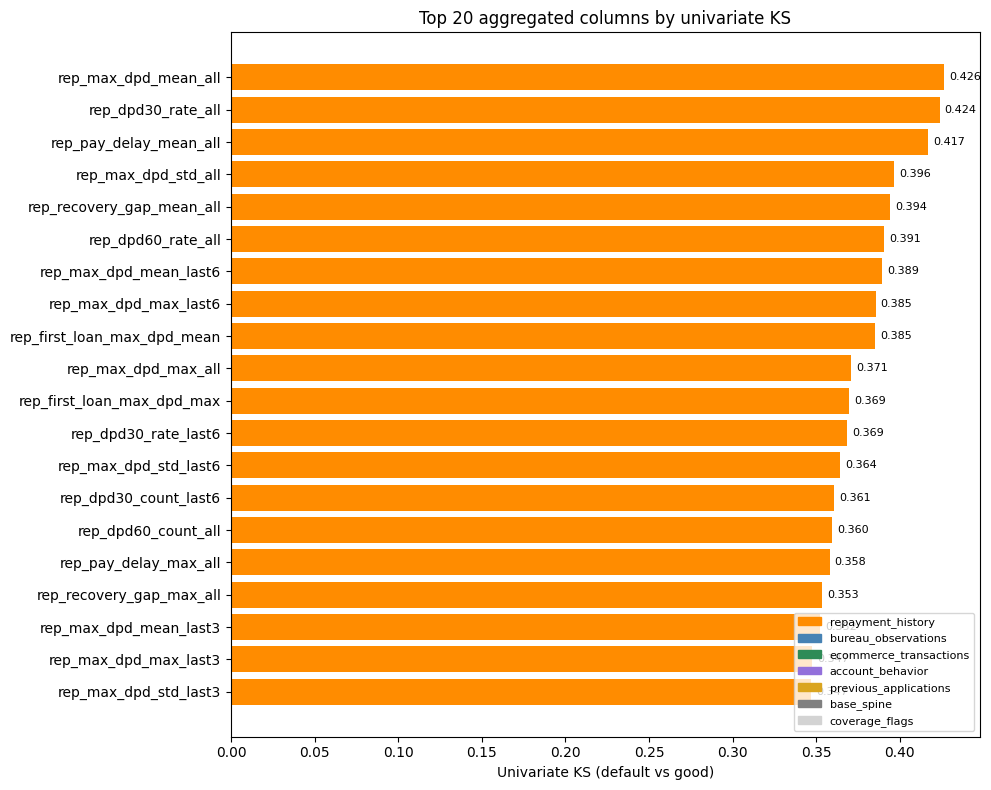


train_aggregated shape: (70000, 357)
test_aggregated shape : (30000, 356)

Saved: c:\Users\pevan\Documents\Rado\codingding\githubprojects\lending-money-probability\output\base_aggregated.parquet
File size: 103.83 MB, reload shape: (100000, 357)
Load in 04_feature_engineering.ipynb with: pd.read_parquet(os.path.join(OUT_DIR, 'base_aggregated.parquet'))


In [10]:
import importlib.util

non_feature_cols = ["application_id", "customer_id", "target", "is_train"]
feature_cols = [
    col for col in base_aggregated.select_dtypes(include=[np.number]).columns
    if col not in non_feature_cols
]
train_part = base_aggregated[base_aggregated["is_train"] == 1]

leaderboard_rows = []
for col in feature_cols:
    valid = train_part[[col, "target"]].dropna()
    if valid[col].nunique() < 2:
        continue
    default_values = valid.loc[valid["target"] == 1, col]
    good_values = valid.loc[valid["target"] == 0, col]
    leaderboard_rows.append({
        "column_name": col,
        "source_table": column_source.get(col, "unknown"),
        "mean_good_0": good_values.mean(),
        "mean_default_1": default_values.mean(),
        "missing_pct": 100 * train_part[col].isna().mean(),
        "univariate_ks": ks_2samp(default_values, good_values).statistic,
    })
ks_leaderboard = pd.DataFrame(leaderboard_rows).sort_values("univariate_ks", ascending=False).reset_index(drop=True)
ks_leaderboard.index = ks_leaderboard.index + 1

print(f"Numeric columns scored: {len(ks_leaderboard)} of {len(feature_cols)}")
print("\nTop 30 aggregated columns by univariate KS (train, 70,000 rows):")
print(ks_leaderboard.head(30).to_string())

print("\nBest KS per source table:")
print(ks_leaderboard.groupby("source_table")["univariate_ks"].agg(["count", "max", "median"]).sort_values("max", ascending=False))

top20 = ks_leaderboard.head(20).iloc[::-1]
source_colors = {
    "repayment_history": "darkorange",
    "bureau_observations": "steelblue",
    "ecommerce_transactions": "seagreen",
    "account_behavior": "mediumpurple",
    "previous_applications": "goldenrod",
    "base_spine": "gray",
    "coverage_flags": "lightgray",
}
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top20["column_name"], top20["univariate_ks"], color=top20["source_table"].map(source_colors))
for y_pos, value in enumerate(top20["univariate_ks"]):
    ax.text(value + 0.003, y_pos, f"{value:.3f}", va="center", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in source_colors.values()]
ax.legend(handles, source_colors.keys(), loc="lower right", fontsize=8)
ax.set_xlabel("Univariate KS (default vs good)")
ax.set_title("Top 20 aggregated columns by univariate KS")
plt.tight_layout()
plt.show()

train_aggregated = base_aggregated[base_aggregated["is_train"] == 1].reset_index(drop=True)
test_aggregated = base_aggregated[base_aggregated["is_train"] == 0].drop(columns=["target"]).reset_index(drop=True)
assert train_aggregated.shape[0] == 70_000
assert test_aggregated.shape[0] == 30_000
print("\ntrain_aggregated shape:", train_aggregated.shape)
print("test_aggregated shape :", test_aggregated.shape)

if importlib.util.find_spec("pyarrow") is not None:
    save_path = os.path.join(OUT_DIR, "base_aggregated.parquet")
    base_aggregated.to_parquet(save_path, index=False)
    reloaded = pd.read_parquet(save_path)
else:
    save_path = os.path.join(OUT_DIR, "base_aggregated.pkl")
    base_aggregated.to_pickle(save_path)
    reloaded = pd.read_pickle(save_path)
ks_leaderboard.to_csv(os.path.join(OUT_DIR, "ks_leaderboard_aggregated.csv"), index_label="rank")

assert reloaded.shape == base_aggregated.shape
print(f"\nSaved: {save_path}")
print(f"File size: {os.path.getsize(save_path) / 1024 ** 2:,.2f} MB, reload shape: {reloaded.shape}")
print("Load in 04_feature_engineering.ipynb with: pd.read_parquet(os.path.join(OUT_DIR, 'base_aggregated.parquet'))")

**What you should see:** 268 numeric columns scored. The top 30 are all from `repayment_history` (KS 0.43 down to 0.32). Best per source: repayment 0.427, ecommerce 0.286, bureau 0.253, base_spine 0.230 (`annual_interest_rate`), previous_applications 0.196, account 0.135. `base_aggregated.parquet` is about 77 MB on disk and reloads with shape (100000, 278).

**Lessons:**
- Repayment dominates the top 30, so the leaderboard hides strong columns from other sources. Check the "best per source" table too.
- Many repayment columns are near-duplicates. Notebook 04 should prune correlated columns before modeling.
- Load in notebook 04 with `pd.read_parquet(os.path.join(OUT_DIR, "base_aggregated.parquet"))`.